In [1]:
# Trainings Pipeline: Unwetterwarnung mit Open-Meteo API

In [2]:
# Feature Group laden
import os
from pathlib import Path

import hopsworks
import pandas as pd
import numpy as np
from dotenv import load_dotenv

project_root = Path.cwd().resolve()
if not (project_root / ".env").exists():
    project_root = project_root.parent
load_dotenv(project_root / ".env")

api_key = os.getenv("HOPSWORKS_API_KEY")
project_name = os.getenv("HOPSWORKS_PROJECT_NAME")
if not api_key or not project_name:
    raise ValueError("HOPSWORKS_API_KEY und HOPSWORKS_PROJECT_NAME müssen gesetzt sein.")

project = hopsworks.login(
    api_key_value=api_key,
    project=project_name,
    host="eu-west.cloud.hopsworks.ai",
    port=443,
)
fs = project.get_feature_store()

weather_fg = fs.get_feature_group(
    name="weather_features_batch",
    version=1,
)

if weather_fg is None:
    raise RuntimeError("Die Feature Group weather_features_batch wurde nicht gefunden.")

print(f"✅ Feature Group geladen: {weather_fg.name} (v{weather_fg.version})")
print(f"📊 Anzahl Features: {len(weather_fg.columns)}")

2026-09-29 18:25:54,672 INFO: Initializing external client
2026-09-29 18:25:54,672 INFO: Base URL: https://eu-west.cloud.hopsworks.ai:443


To ensure compatibility please install the latest bug fix release matching the minor version of your backend (5.1) by running 'pip install hopsworks==5.1.*'
2026-09-29 18:25:57,504 INFO: Python Engine initialized.



Logged in to project, explore it here https://eu-west.cloud.hopsworks.ai:443/p/44167
✅ Feature Group geladen: weather_features_batch (v1)
📊 Anzahl Features: 30


In [3]:
# Feature View erstellen (Query mit Features + Label)

feature_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "surface_pressure",
    "cloud_cover",
    "wind_speed_10m",
    "wind_gusts_10m",
    "cape",
    "precip_rolling_sum_3h",
    "precip_rolling_sum_6h",
    "precip_rolling_sum_12h",
    "wind_gust_max_3h",
    "wind_gust_max_6h",
    "wind_gust_max_12h",
    "pressure_mean_3h",
    "pressure_mean_6h",
    "pressure_mean_12h",
    "pressure_change_3h",
    "pressure_drop_rate",
    "wind_gust_anomaly",
    "temp_change_3h",
]
label_column = "is_severe_weather"

available_columns = {column.name for column in weather_fg.columns}
missing_columns = [
    column for column in feature_columns + [label_column]
    if column not in available_columns
]
if missing_columns:
    raise ValueError(f"Fehlende Spalten in weather_features_batch: {missing_columns}")

query = weather_fg.select(feature_columns + [label_column])
feature_view = fs.get_or_create_feature_view(
    name="severe_weather_fv",
    version=1,
    description="Feature View für eine Unwetterprognose drei Stunden im Voraus",
    query=query,
    labels=[label_column],
)

print(f"✅ Feature View erstellt: {feature_view.name} (v{feature_view.version})")

✅ Feature View erstellt: severe_weather_fv (v1)


In [4]:
# Modell trainieren und evaluieren
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# Drei-Stunden-Zielhorizont des trainierten Unwetterlabels.
TARGET_HORIZON_HOURS = 3

# Trainingsdaten aus der Feature View laden
training_dataset_version, _ = feature_view.create_training_data(
    data_format="csv",
    write_options={"wait_for_job": True},
)
X, y = feature_view.get_training_data(
    training_dataset_version=training_dataset_version
)
y[label_column] = pd.to_numeric(y[label_column], errors="coerce").fillna(0).astype(int)

if y[label_column].nunique() < 2:
    raise ValueError(
        "Das Trainingsset enthält nur eine Label-Klasse. "
        "Bitte mehr historische Daten laden oder die Label-Schwellenwerte prüfen."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y[label_column],
)

classes = np.unique(y_train[label_column])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train[label_column],
)
class_weight_dict = dict(zip(classes, weights))

# XGBoost Classifier für tabulare Wetterdaten
model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    scale_pos_weight=class_weight_dict.get(1, 1) / class_weight_dict.get(0, 1),
    eval_metric="aucpr",
    random_state=42,
)

model.fit(
    X_train,
    y_train[label_column].astype(int),
    eval_set=[(X_test, y_test[label_column].astype(int))],
    verbose=False,
)

predictions = model.predict(X_test).astype(int)
print(f"✅ Modell trainiert: Zielhorizont {TARGET_HORIZON_HOURS} Stunden")
print(classification_report(
    y_test[label_column].astype(int),
    predictions,
    labels=[0, 1],
    zero_division=0,
))

Training dataset job started successfully, you can follow the progress at 
http://eu-west.cloud.hopsworks.ai/p/44167/jobs/named/severe_weather_fv_1_create_fv_td_29092026182609/executions


2026-09-29 18:26:15,168 INFO: Waiting for execution to finish. Current state: INITIALIZING. Final status: UNDEFINED
2026-09-29 18:26:18,291 INFO: Waiting for execution to finish. Current state: SUBMITTED. Final status: UNDEFINED
2026-09-29 18:26:21,416 INFO: Waiting for execution to finish. Current state: RUNNING. Final status: UNDEFINED
2026-09-29 18:27:58,255 INFO: Waiting for execution to finish. Current state: FINISHED. Final status: SUCCEEDED
2026-09-29 18:27:58,694 INFO: Waiting for log aggregation to finish.
2026-09-29 18:27:58,695 INFO: Execution finished successfully.
2026-09-29 18:28:00,581 INFO: Provenance cached data - overwriting last accessed/created training dataset from 32 to 32.


✅ Modell trainiert: Zielhorizont 3 Stunden
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       401
           1       0.59      0.66      0.62        29

    accuracy                           0.95       430
   macro avg       0.78      0.81      0.80       430
weighted avg       0.95      0.95      0.95       430



📋 Classification Report:
               precision    recall  f1-score   support

Kein Unwetter       0.97      0.97      0.97       401
     Unwetter       0.59      0.66      0.62        29

     accuracy                           0.95       430
    macro avg       0.78      0.81      0.80       430
 weighted avg       0.95      0.95      0.95       430

🎯 ROC-AUC: 0.9345
🎯 F1-Score: 0.6230


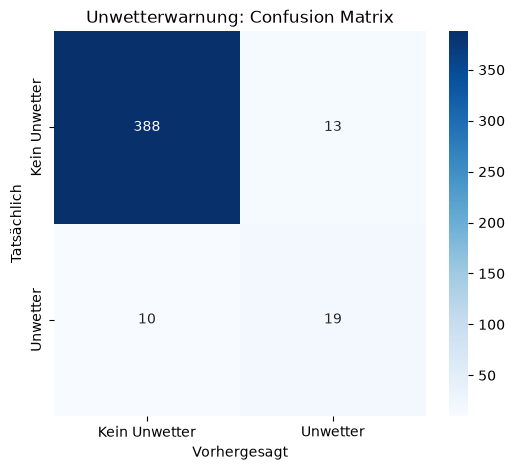

In [5]:
# Modell evaluieren
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Vorhersagen
y_true = y_test[label_column].astype(int).to_numpy()
y_pred = model.predict(X_test).astype(int)
y_pred_proba = model.predict_proba(X_test)[:, 1]

print("📋 Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Kein Unwetter", "Unwetter"],
    zero_division=0,
))

f1 = f1_score(y_true, y_pred, zero_division=0)
if np.unique(y_true).size == 2:
    roc_auc = roc_auc_score(y_true, y_pred_proba)
    print(f"🎯 ROC-AUC: {roc_auc:.4f}")
else:
    roc_auc = float("nan")
    print("⚠️ ROC-AUC nicht berechnet: Im Testset ist nur eine Klasse vorhanden.")

print(f"🎯 F1-Score: {f1:.4f}")

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Kein Unwetter", "Unwetter"],
    yticklabels=["Kein Unwetter", "Unwetter"],
)
plt.title("Unwetterwarnung: Confusion Matrix")
plt.ylabel("Tatsächlich")
plt.xlabel("Vorhergesagt")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

🏆 Top 10 wichtigste Features:
                   feature  importance
7           wind_gusts_10m    0.209148
9    precip_rolling_sum_3h    0.089278
21          temp_change_3h    0.072620
11  precip_rolling_sum_12h    0.057186
15        pressure_mean_3h    0.056809
2            precipitation    0.052932
18      pressure_change_3h    0.045801
4         surface_pressure    0.039726
1     relative_humidity_2m    0.037078
17       pressure_mean_12h    0.035853


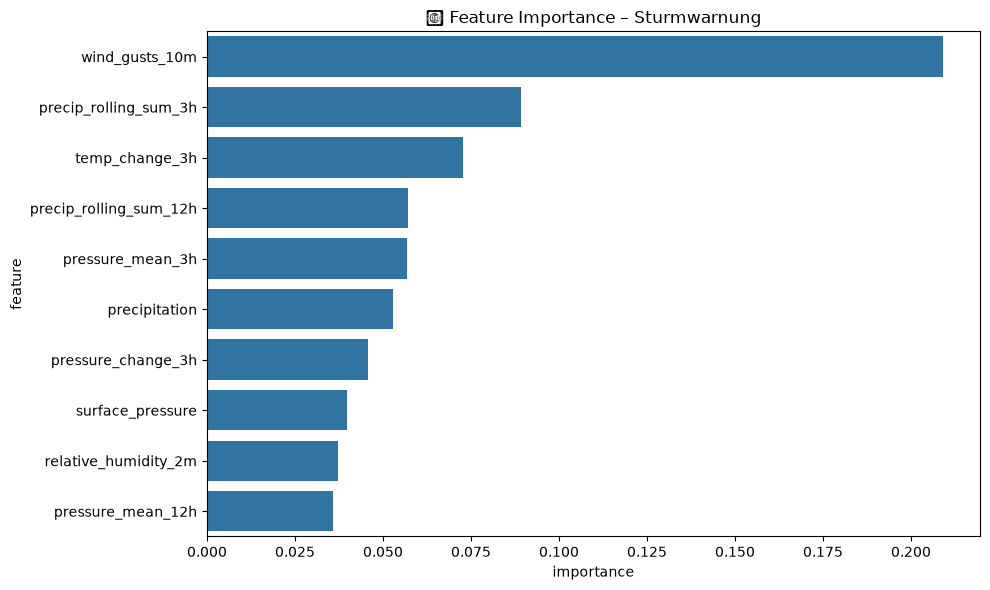

In [6]:
# Feature Importance
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

print("🏆 Top 10 wichtigste Features:")
print(importance_df.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(10), x="importance", y="feature")
plt.title("🌟 Feature Importance – Sturmwarnung")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Modell speichern und Metriken für die Model Registry vorbereiten
import json
import joblib
import math
import os

model_dir = "severe_weather_model"
os.makedirs(model_dir, exist_ok=True)

model_path = os.path.join(model_dir, "model.joblib")
joblib.dump(model, model_path)
print(f"✅ Modell lokal gespeichert: {model_path}")

metrics = {
    "f1_score": float(f1),
    "n_train_samples": int(len(X_train)),
    "n_test_samples": int(len(X_test)),
    "positive_class_ratio": float(y_train[label_column].mean()),
    "forecast_horizon_hours": TARGET_HORIZON_HOURS,
}

if math.isfinite(float(roc_auc)):
    metrics["roc_auc"] = float(roc_auc)
else:
    print("⚠️ ROC-AUC wird nicht registriert, weil sie nicht definiert ist.")

with open(os.path.join(model_dir, "metrics.json"), "w") as metrics_file:
    json.dump(metrics, metrics_file, indent=2, allow_nan=False)

print(f"📊 Metriken gespeichert: {metrics}")

✅ Modell lokal gespeichert: severe_weather_model/model.joblib
📊 Metriken gespeichert: {'f1_score': 0.6229508196721312, 'n_train_samples': 1718, 'n_test_samples': 430, 'positive_class_ratio': 0.06635622817229336, 'forecast_horizon_hours': 3, 'roc_auc': 0.9344741594290137}


In [8]:
# Upload in Hopsworks Model Registry
from hsml.schema import Schema
from hsml.model_schema import ModelSchema

# Model Registry abrufen
mr = project.get_model_registry()

# Input/Output Schema definieren (für Dokumentation & Validation)
input_schema = Schema(X_train)
output_schema = Schema(y_train[[label_column]])
model_schema = ModelSchema(input_schema=input_schema, output_schema=output_schema)

# Modell-Objekt in Registry erstellen
severe_weather_model = mr.python.create_model(
    name="severe_weather_classifier",
    metrics=metrics,
    model_schema=model_schema,
    input_example=X_train.sample(1),
    description="XGBoost-Modell zur Unwetterwarnung etwa drei Stunden im Voraus "
                "basierend auf Open-Meteo-Wetterdaten (Wind, Niederschlag, Luftdruck-Trends)",
    feature_view=feature_view  # 🔗 Lineage zur Feature View
)

# Modell-Verzeichnis hochladen
severe_weather_model.save(model_dir)

print(f"Modell in Registry hochgeladen!")
print(f"Name: {severe_weather_model.name}")
print(f"Version: {severe_weather_model.version}")
print(f"Model ID: {severe_weather_model.id}")

  0%|          | 0/6 [00:00<?, ?it/s]

Moving model files from 'severe_weather_model' to the model registry... This is the default behavior. Set keep_original_files=True to copy files instead.


Uploading /workspaces/fhnw_cas_aiops_project1_weather_forcasts/02_Trainings_Pipeline/severe_weather_model/mode…

Uploading /workspaces/fhnw_cas_aiops_project1_weather_forcasts/02_Trainings_Pipeline/severe_weather_model/metr…

Uploading /tmp/tmpa23ai1r_/input_example.json: 0.000%|          | 0/244 elapsed<00:00 remaining<?

Uploading /tmp/tmpa23ai1r_/model_schema.json: 0.000%|          | 0/1924 elapsed<00:00 remaining<?

Model created, explore it at https://eu-west.cloud.hopsworks.ai:443/p/44167/models/severe_weather_classifier/21
Modell in Registry hochgeladen!
Name: severe_weather_classifier
Version: 21
Model ID: severe_weather_classifier_21
